# Task 3 — Verifikasi: Distorsi Data, Pola Spektrum per Klaster, dan Uji k = 4 terhadap k = 9

**Ruang lingkup.** Notebook ini melengkapi dua hal pada Task 3 dan memeriksa satu temuan dari tahap 3.
1. **Butir (a), eksplorasi distorsi.** Distorsi citra (rotasi, skala, kecerahan, perbedaan mikroskop) dan distorsi spektrum (pergeseran, garis dasar, lonjakan) belum diukur secara langsung pada tahap sebelumnya. Bagian 1 mengukurnya.
2. **Temuan pada hasil tahap 3.** Pada `cluster.csv` (k = 9), spektrum rata-rata sembilan klaster ternyata hanya membentuk beberapa pola yang berbeda, dan beberapa klaster yang berbagi pola hampir seluruhnya berasal dari satu mikroskop. Bagian 2 sampai 4 menguji temuan ini pada data mentah.
3. **Butir (e), kriteria jumlah klaster.** Bagian 4 menambahkan kriteria ketiga yang berdiri sendiri, yaitu jumlah pola spektrum yang berbeda, di samping kesepakatan gambar dan spektrum dari tahap 2b.

**Prinsip.** Notebook ini **tidak menimpa** `cluster.csv`. Hasilnya berupa angka, grafik, dan satu berkas kandidat `hasil/cluster_k4.csv`; keputusan memakai kandidat atau tetap pada k = 9 diambil kelompok setelah membaca hasilnya, dan harus dilaporkan sebagai keputusan yang diambil setelah melihat data.

**Alur.** 0 Persiapan → 1 Eksplorasi distorsi → 2 Pola spektrum per klaster → 3 Mikroskop di dalam grup → 4 Perbandingan k = 4 dan k = 9 → 5 Kandidat dan kesimpulan → 6 Commit.

In [3]:
AKUN_GITHUB = 'rafiptrnto'
EMAIL_GITHUB = 'rafiputranto665@gmail.com'
REPO = '/content/UTSDEEPLEARNING'
DATA = '/content/data'
SEED = 0
N_EKSPLORASI = 6000        # sampel acak untuk ukuran distorsi
N_SIL = 8000
AMBANG_KORELASI = 0.98     # dua klaster dianggap berpola spektrum sama bila korelasi profil rata-ratanya di atas ini

import numpy, pandas, sklearn, scipy, sys, warnings, os, json, time
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | scipy 1.16.3


In [4]:
if not os.path.exists(f'{DATA}/clustering.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists(REPO):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git {REPO}
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git checkout main
!git pull --no-edit upstream main
!git checkout -B task3-verifikasi
!mkdir -p kode/task3_cluster/hasil
!ls . kode/task3_cluster

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 277, done.
remote: Counting objects: 100% (102/102), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 277 (delta 24), reused 57 (delta 10), pack-reused 175 (from 2)
Receiving objects: 100% (277/277), 70.67 MiB | 27.26 MiB/s, done.
Resolving deltas: 100% (72/72), done.
/content/UTSDEEPLEARNING
Already on 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Already up to date.
Switched to a new branch 'task3-verifikasi'
.:
cluster.csv  kontribusi.md	       prediksi_rul.csv
kode	     prediksi_klasifikasi.csv  README.md

kode/task3_cluster:
bobot		clu_model.py  serah_terima_v2	    task3_representasi.ipynb
clu_cluster.py	emb	      task3_dec.ipynb
clu_data.py	hasil	      task3_klaster.ipynb
clu_dec.py	serah_terima  task3_lanjutan.ipynb


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (normalized_mutual_info_score as nmi, adjusted_rand_score as ari,
                             silhouette_score, davies_bouldin_score)
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform

OUT = f'{REPO}/kode/task3_cluster/hasil'
EMB = f'{REPO}/kode/task3_cluster/emb'
z = np.load(f'{DATA}/clustering.npz')
gam, spk = z['gambar'], z['spektrum'].astype(np.float32)
meta = pd.read_csv(f'{DATA}/clustering_meta.csv')
if 'indeks' in meta.columns:
    meta = meta.sort_values('indeks').reset_index(drop=True)
mik = meta['mikroskop'].astype(str).values
sub = pd.read_csv(f'{REPO}/cluster.csv')
assert len(sub) == len(meta) and (sub['id_sampel'].values == meta['id_sampel'].values).all(), "urutan cluster.csv tidak sama dengan clustering_meta.csv"
lab9 = sub['cluster'].values.astype(int)
K9 = len(np.unique(lab9))
print("sampel:", len(meta), "| mikroskop:", dict(pd.Series(mik).value_counts()), "| klaster di cluster.csv:", K9)
print("spektrum: nilai tidak hingga =", int((~np.isfinite(spk)).sum()))
INFO = {'k_cluster_csv': int(K9)}

sampel: 36000 | mikroskop: {'M1': np.int64(21636), 'M2': np.int64(14364)} | klaster di cluster.csv: 9
spektrum: nilai tidak hingga = 0


## 1. Eksplorasi distorsi (butir a)

Semua ukuran di bawah dihitung pada sampel acak (`N_EKSPLORASI`) dan dipisah menurut mikroskop, karena yang dicari adalah apakah distorsi berbeda antar alat.

**Citra.**
- *Kecerahan dan kontras:* rerata dan simpangan baku piksel per citra.
- *Rotasi:* arah dominan tekstur, dari tensor struktur gradien (sudut 0 sampai 180 derajat). Sebaran yang merata berarti orientasi bukan petunjuk material dan bersifat sebagai distorsi; sebaran yang menumpuk berarti ada arah khas.
- *Skala:* frekuensi spasial rerata dari spektrum daya 2D (frekuensi tinggi berarti tekstur halus atau diperkecil).

**Spektrum.**
- *Pergeseran:* lag korelasi silang terhadap profil rata-rata grup spektrumnya (bagian 2), pada rentang ±8 saluran.
- *Garis dasar:* median dari 20% nilai terendah tiap spektrum.
- *Lonjakan:* jumlah titik terisolasi yang menyimpang dari kedua tetangganya ke arah yang sama lebih dari 8 kali derau global (derau diduga dari median selisih kedua, yang tidak terpengaruh puncak yang mulus).
- *Amplitudo:* nilai maksimum spektrum.

mikroskop                  M1     M2
kecerahan         mean  0.500  0.572
                  std   0.047  0.043
kontras           mean  0.078  0.078
                  std   0.021  0.018
frekuensi_spasial mean  0.163  0.202
                  std   0.061  0.062
koherensi_arah    mean  0.424  0.301
                  std   0.394  0.304


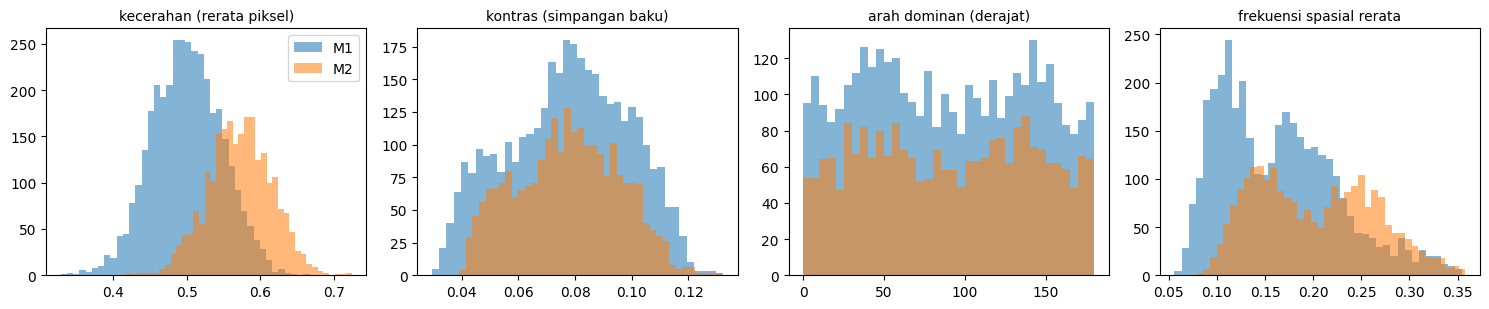

histogram arah (18 bin): [312, 309, 325, 389, 387, 387, 331, 306, 311, 274, 329, 338, 321, 387, 382, 333, 269, 310] | rasio maks/min: 1.45


In [6]:
rng = np.random.RandomState(SEED)
sub_idx = rng.choice(len(gam), N_EKSPLORASI, replace=False)
G = gam[sub_idx].astype(np.float32) / 255.0
M = mik[sub_idx]

# kecerahan dan kontras
kec = G.reshape(len(G), -1).mean(1); kon = G.reshape(len(G), -1).std(1)

# arah dominan (tensor struktur) dan frekuensi spasial rerata
gy, gx = np.gradient(G, axis=(1, 2))
Jxx, Jyy, Jxy = (gx*gx).mean((1, 2)), (gy*gy).mean((1, 2)), (gx*gy).mean((1, 2))
sudut = (0.5 * np.degrees(np.arctan2(2*Jxy, Jxx - Jyy))) % 180
koheren = np.sqrt((Jxx - Jyy)**2 + 4*Jxy**2) / (Jxx + Jyy + 1e-9)
F = np.abs(np.fft.fftshift(np.fft.fft2(G - G.mean((1, 2), keepdims=True)), axes=(1, 2)))**2
fy, fx = np.meshgrid(np.fft.fftshift(np.fft.fftfreq(G.shape[1])), np.fft.fftshift(np.fft.fftfreq(G.shape[2])), indexing='ij')
fr = np.sqrt(fx**2 + fy**2)
frek = (F * fr).sum((1, 2)) / (F.sum((1, 2)) + 1e-9)

dfc = pd.DataFrame({'mikroskop': M, 'kecerahan': kec, 'kontras': kon, 'frekuensi_spasial': frek, 'koherensi_arah': koheren})
print(dfc.groupby('mikroskop').agg(['mean', 'std']).round(3).T.to_string())

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for m in sorted(np.unique(M)):
    s = M == m
    ax[0].hist(kec[s], 40, alpha=.55, label=m); ax[1].hist(kon[s], 40, alpha=.55, label=m)
    ax[2].hist(sudut[s], 36, alpha=.55, label=m); ax[3].hist(frek[s], 40, alpha=.55, label=m)
for a, t in zip(ax, ['kecerahan (rerata piksel)', 'kontras (simpangan baku)', 'arah dominan (derajat)', 'frekuensi spasial rerata']):
    a.set_title(t, fontsize=10)
ax[0].legend(); plt.tight_layout(); plt.show()

uniform = np.histogram(sudut, 18, range=(0, 180))[0]
INFO['citra'] = {m: dict(kecerahan=float(kec[M == m].mean()), kontras=float(kon[M == m].mean()), frekuensi=float(frek[M == m].mean())) for m in sorted(np.unique(M))}
INFO['arah'] = dict(rasio_maks_min_per_18_bin=float(uniform.max() / max(1, uniform.min())), koherensi_rerata=float(koheren.mean()))
print("histogram arah (18 bin):", uniform.tolist(), "| rasio maks/min:", round(uniform.max() / max(1, uniform.min()), 2))

## 2. Pola spektrum per klaster pada `cluster.csv`

Untuk tiap klaster dihitung spektrum rata-ratanya. Dua klaster dianggap **berpola sama** bila korelasi profil rata-ratanya di atas `AMBANG_KORELASI`. Grup pola dibentuk dengan pengelompokan hierarkis (tautan rata-rata, jarak 1 − korelasi) pada profil rata-rata sembilan klaster. Pemeriksaan penting: bila klaster dibedakan oleh komposisi, profil rata-ratanya harus berbeda tajam; bila hanya dibedakan oleh tekstur atau mikroskop, profilnya hampir sama.

tinggi penggabungan (1 - korelasi), urut naik: [0.0002, 0.0002, 0.0003, 0.0004, 0.0009, 0.8027, 1.041, 1.1606]
jumlah pola spektrum berbeda pada ambang korelasi 0.98: 4
klaster -> grup pola: {0: 1, 1: 0, 2: 2, 3: 0, 4: 1, 5: 3, 6: 3, 7: 1, 8: 2}
jumlah pola menurut celah terbesar antar penggabungan: 4


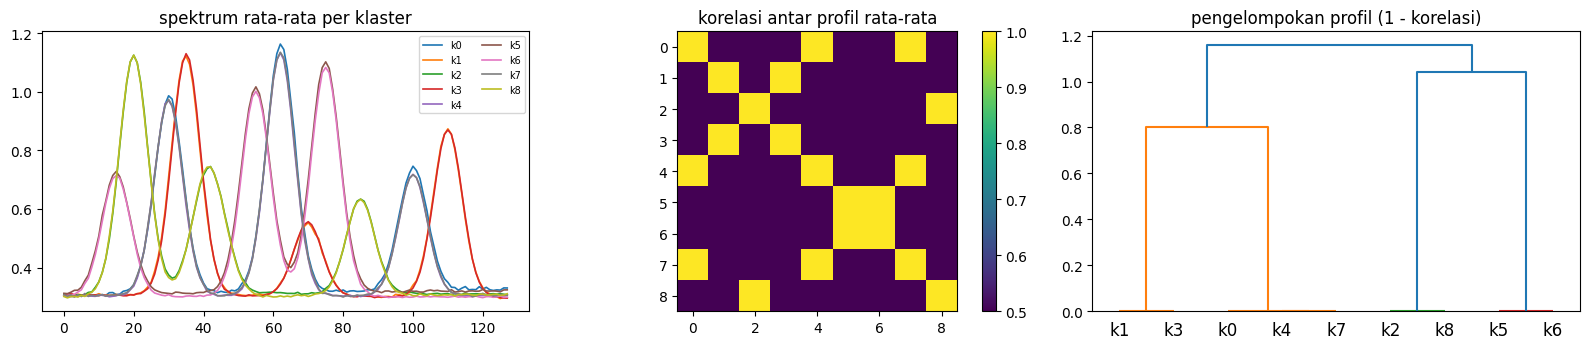

ukuran grup pola: {0: np.int64(8675), 1: np.int64(8551), 2: np.int64(10107), 3: np.int64(8667)}


In [7]:
prof = np.array([spk[lab9 == k].mean(0) for k in range(K9)])
R = np.corrcoef(prof)
D = pdist(prof, 'correlation')
Zl = linkage(D, 'average')
tinggi = Zl[:, 2]
print("tinggi penggabungan (1 - korelasi), urut naik:", np.round(tinggi, 4).tolist())
n_grup = int((tinggi > 1 - AMBANG_KORELASI).sum() + 1)
grp_c = fcluster(Zl, t=1 - AMBANG_KORELASI, criterion='distance')
print(f"jumlah pola spektrum berbeda pada ambang korelasi {AMBANG_KORELASI}: {len(np.unique(grp_c))}")
cmap = {k: int(grp_c[k]) - 1 for k in range(K9)}
print("klaster -> grup pola:", cmap)
INFO['grup_pola'] = dict(n=int(len(np.unique(grp_c))), peta={int(k): int(v) for k, v in cmap.items()}, tinggi=[float(t) for t in tinggi])

# celah terbesar antar tinggi penggabungan sebagai kriteria jumlah pola tanpa ambang tetap
gap = np.diff(np.r_[0, tinggi]); k_gap = K9 - int(np.argmax(gap))
INFO['jumlah_pola_celah_terbesar'] = int(k_gap)
print("jumlah pola menurut celah terbesar antar penggabungan:", k_gap)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for k in range(K9): ax[0].plot(prof[k], label=f'k{k}', lw=1.2)
ax[0].set_title('spektrum rata-rata per klaster'); ax[0].legend(ncol=2, fontsize=7)
im = ax[1].imshow(R, vmin=0.5, vmax=1, cmap='viridis'); ax[1].set_title('korelasi antar profil rata-rata'); plt.colorbar(im, ax=ax[1])
dendrogram(Zl, ax=ax[2], labels=[f'k{k}' for k in range(K9)]); ax[2].set_title('pengelompokan profil (1 - korelasi)')
plt.tight_layout(); plt.show()

# sampel ke grup pola
grp_sampel = np.array([cmap[k] for k in lab9])
print("ukuran grup pola:", dict(pd.Series(grp_sampel).value_counts().sort_index()))

mikroskop               M1     M2
lag_pergeseran mean  0.033  0.039
               std   2.544  2.540
garis_dasar    mean  0.168  0.164
               std   0.281  0.283
amplitudo_maks mean  1.753  1.746
               std   0.896  0.877
titik_lonjakan mean  0.249  0.246
               std   0.499  0.518
sebaran lag: {-8: np.int64(21), -7: np.int64(22), -6: np.int64(56), -5: np.int64(128), -4: np.int64(260), -3: np.int64(456), -2: np.int64(643), -1: np.int64(875), 0: np.int64(925), 1: np.int64(942), 2: np.int64(720), 3: np.int64(471), 4: np.int64(265), 5: np.int64(124), 6: np.int64(52), 7: np.int64(27), 8: np.int64(13)}


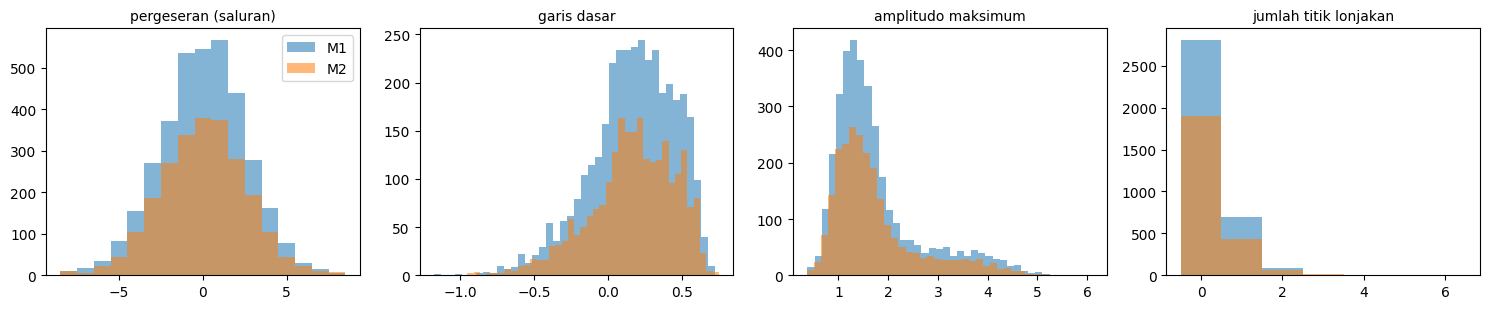

In [8]:
# Distorsi spektrum (bagian 1), diukur terhadap profil grup masing-masing
rs = np.random.RandomState(SEED + 1)
si = rs.choice(len(spk), N_EKSPLORASI, replace=False)
S = spk[si]; Ms = mik[si]; gs = grp_sampel[si]
PG = np.array([spk[grp_sampel == g].mean(0) for g in range(len(np.unique(grp_sampel)))])

lags = np.arange(-8, 9)
def lag_terbaik(x, ref):
    xc, rc = x - x.mean(), ref - ref.mean()
    sk = [np.dot(np.roll(xc, -l), rc) for l in lags]
    return lags[int(np.argmax(sk))]
lag = np.array([lag_terbaik(S[i], PG[gs[i]]) for i in range(len(S))])
dasar = np.sort(S, axis=1)[:, :int(0.2 * S.shape[1])].mean(1)
amp = S.max(1)
# lonjakan: titik terisolasi yang menyimpang dari kedua tetangganya ke arah yang sama, lebih dari 8 kali derau global
d2 = 2 * S[:, 1:-1] - S[:, :-2] - S[:, 2:]
sigma = 1.4826 * np.median(np.abs(d2 - np.median(d2))) / np.sqrt(6) + 1e-9
a_ = S[:, 1:-1] - S[:, :-2]; b_ = S[:, 1:-1] - S[:, 2:]
n_spike = ((a_ * b_ > 0) & (np.minimum(np.abs(a_), np.abs(b_)) > 8 * sigma)).sum(1)
INFO_SIGMA = float(sigma)
dsp = pd.DataFrame({'mikroskop': Ms, 'lag_pergeseran': lag, 'garis_dasar': dasar, 'amplitudo_maks': amp, 'titik_lonjakan': n_spike})
print(dsp.groupby('mikroskop').agg(['mean', 'std']).round(3).T.to_string())
print("sebaran lag:", dict(pd.Series(lag).value_counts().sort_index()))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for m in sorted(np.unique(Ms)):
    s = Ms == m
    ax[0].hist(lag[s], bins=np.arange(-8.5, 9.5, 1), alpha=.55, label=m); ax[1].hist(dasar[s], 40, alpha=.55)
    ax[2].hist(amp[s], 40, alpha=.55); ax[3].hist(n_spike[s], bins=np.arange(-.5, max(6, n_spike.max()) + 1.5, 1), alpha=.55)
for a, t in zip(ax, ['pergeseran (saluran)', 'garis dasar', 'amplitudo maksimum', 'jumlah titik lonjakan']): a.set_title(t, fontsize=10)
ax[0].legend(); plt.tight_layout(); plt.show()
INFO['spektrum'] = {m: dict(lag_std=float(lag[Ms == m].std()), dasar=float(dasar[Ms == m].mean()), amp=float(amp[Ms == m].mean()), lonjakan=float(n_spike[Ms == m].mean())) for m in sorted(np.unique(Ms))}

## 3. Mikroskop di dalam grup pola

Bila klaster-klaster yang berpola spektrum sama hanya berbeda karena alat, komposisi mikroskopnya akan sangat timpang (misalnya hampir semua M1 pada satu klaster dan campuran pada klaster lain). Diukur: komposisi mikroskop per klaster, dan NMI antara pembagian klaster di dalam tiap grup dengan mikroskop.

In [9]:
tab = pd.crosstab(lab9, mik, normalize='index').round(3); tab['n'] = pd.Series(lab9).value_counts().sort_index().values
tab['grup_pola'] = [cmap[k] for k in tab.index]
print(tab.to_string())
rows = []
for g in sorted(np.unique(grp_sampel)):
    s = grp_sampel == g
    kl = np.unique(lab9[s])
    rows.append(dict(grup=g, klaster=kl.tolist(), n=int(s.sum()),
                     nmi_pembagian_vs_mikroskop=(float(nmi(lab9[s], mik[s])) if len(kl) > 1 else np.nan),
                     proporsi_M1=float((mik[s] == 'M1').mean())))
dg = pd.DataFrame(rows); print(dg.round(3).to_string())
INFO['mikroskop_dalam_grup'] = dg.to_dict('records')
INFO['mik_nmi_k9_seluruh'] = float(nmi(lab9, mik))
print("NMI seluruh cluster.csv vs mikroskop:", round(INFO['mik_nmi_k9_seluruh'], 4))

col_0     M1     M2     n  grup_pola
row_0                               
0      0.990  0.010  1261          1
1      0.709  0.291  3577          0
2      0.584  0.416  5591          2
3      0.516  0.484  5098          0
4      0.617  0.383  4896          1
5      0.921  0.079  3679          3
6      0.380  0.620  4988          3
7      0.379  0.621  2394          1
8      0.607  0.393  4516          2
   grup    klaster      n  nmi_pembagian_vs_mikroskop  proporsi_M1
0     0     [1, 3]   8675                       0.028        0.596
1     1  [0, 4, 7]   8551                       0.118        0.606
2     2     [2, 8]  10107                       0.000        0.594
3     3     [5, 6]   8667                       0.252        0.610
NMI seluruh cluster.csv vs mikroskop: 0.0488


## 4. Perbandingan k = 4 dan k = 9 dengan kriteria yang sama

Kandidat k = 4 dibentuk dengan **menggabungkan klaster yang berpola spektrum sama** (bukan pengelompokan baru), sehingga perbandingannya langsung terhadap `cluster.csv`. Untuk jumlah klaster yang dihitung ada tiga kriteria yang berdiri sendiri:
1. **Kesepakatan gambar dan spektrum** (tahap 2b): ARI antara K-Means pada embedding gambar dan pada embedding spektrum, per k.
2. **Jumlah pola spektrum berbeda** (bagian 2): dari ambang korelasi dan dari celah terbesar antar penggabungan.
3. **Kemandirian terhadap mikroskop**: NMI klaster dengan mikroskop pada tiap k.

Ukuran mutu internal (silhouette, Davies-Bouldin) dihitung pada embedding yang sama dengan tahap 3 (`fusi_simclr_concat`) dan pada `pca_spektrum`, pada sub-sampel acak.

In [10]:
def muat_emb(n): return np.load(f'{EMB}/{n}.npy').astype(np.float32)
E_f, E_s = muat_emb('fusi_simclr_concat'), muat_emb('pca_spektrum')
assert len(E_f) == len(lab9)
n_grp = len(np.unique(grp_sampel))
lab4 = grp_sampel.copy()

si2 = np.random.RandomState(SEED).choice(len(lab9), N_SIL, replace=False)
def ukur(nama, lab):
    r = dict(kandidat=nama, k=int(len(np.unique(lab))), ukuran_min=float(pd.Series(lab).value_counts(normalize=True).min()),
             nmi_mikroskop=float(nmi(lab, mik)))
    for en, E in (('fusi_simclr_concat', E_f), ('pca_spektrum', E_s)):
        r[f'sil_{en}'] = float(silhouette_score(E[si2], lab[si2])); r[f'dbi_{en}'] = float(davies_bouldin_score(E[si2], lab[si2]))
    return r
tabel = pd.DataFrame([ukur('cluster.csv (k = %d)' % K9, lab9), ukur(f'digabung menurut pola spektrum (k = {n_grp})', lab4)])
print(tabel.round(3).T.to_string())
INFO['perbandingan'] = tabel.to_dict('records')
INFO['ari_k9_vs_gabungan'] = float(ari(lab9, lab4)); INFO['nmi_k9_vs_gabungan'] = float(nmi(lab9, lab4))
print("ARI k9 vs gabungan:", round(INFO['ari_k9_vs_gabungan'], 3), "| NMI:", round(INFO['nmi_k9_vs_gabungan'], 3))

                                          0                                       1
kandidat                cluster.csv (k = 9)  digabung menurut pola spektrum (k = 4)
k                                         9                                       4
ukuran_min                            0.035                                   0.238
nmi_mikroskop                         0.049                                     0.0
sil_fusi_simclr_concat                0.156                                   0.143
dbi_fusi_simclr_concat                1.993                                   2.534
sil_pca_spektrum                     -0.003                                    0.15
dbi_pca_spektrum                     63.633                                    2.26
ARI k9 vs gabungan: 0.592 | NMI: 0.787


                  pasangan  k       ari       nmi  ari_acak
0  ae_gambar x ae_spektrum  2  0.000008  0.000025 -0.000014
1  ae_gambar x ae_spektrum  3  0.000242  0.000864 -0.000106
2  ae_gambar x ae_spektrum  4  0.027151  0.057095 -0.000460
    k  sil_pca_spektrum  ari_dengan_grup_pola  nmi_dengan_grup_pola  nmi_mikroskop
0   2             0.260                 0.001                 0.001            0.0
1   3             0.167                 0.001                 0.001            0.0
2   4             0.167                 0.157                 0.213            0.0
3   5             0.190                 0.269                 0.361            0.0
4   6             0.192                 0.349                 0.447            0.0
5   7             0.182                 0.363                 0.467            0.0
6   8             0.185                 0.383                 0.502            0.0
7   9             0.185                 0.379                 0.516            0.0
8  10        

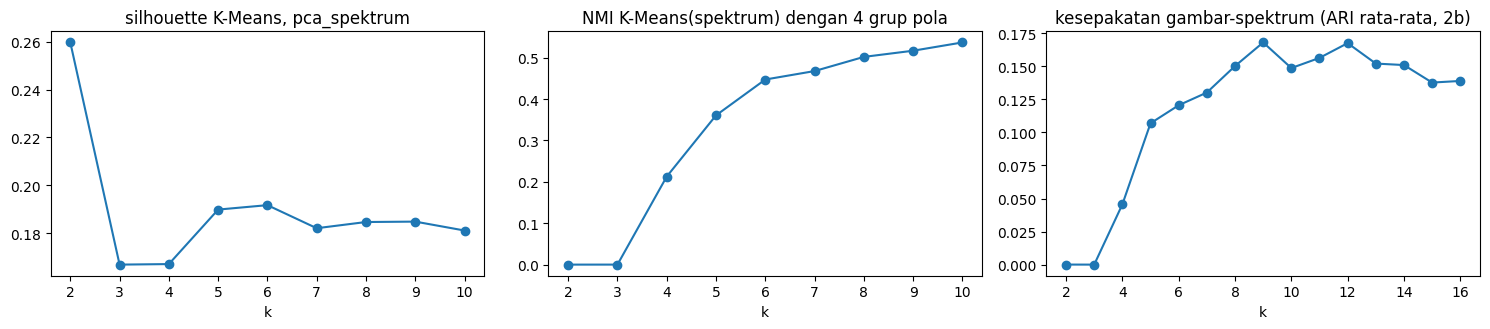

In [11]:
# Kesepakatan gambar-spektrum menurut k (dari tahap 2b) dan K-Means pada spektrum untuk tiap k
try:
    ks = pd.read_csv(f'{OUT}/kesepakatan_modalitas_k2_16.csv'); print(ks.head(3).to_string())
except Exception as e:
    ks = None; print("berkas kesepakatan 2b tidak terbaca:", e)

# K-Means pada pca_spektrum untuk k = 2..10: seberapa tajam strukturnya, dan seberapa cocok dengan grup pola
rows = []
for k in range(2, 11):
    l = KMeans(k, n_init=5, random_state=SEED).fit_predict(E_s)
    rows.append(dict(k=k, sil_pca_spektrum=float(silhouette_score(E_s[si2], l[si2])), ari_dengan_grup_pola=float(ari(grp_sampel, l)),
                     nmi_dengan_grup_pola=float(nmi(grp_sampel, l)), nmi_mikroskop=float(nmi(l, mik))))
ts = pd.DataFrame(rows); print(ts.round(3).to_string())
INFO['kmeans_spektrum_per_k'] = ts.to_dict('records')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(ts['k'], ts['sil_pca_spektrum'], 'o-'); ax[0].set_title('silhouette K-Means, pca_spektrum'); ax[0].set_xlabel('k')
ax[1].plot(ts['k'], ts['nmi_dengan_grup_pola'], 'o-'); ax[1].set_title(f'NMI K-Means(spektrum) dengan {n_grp} grup pola'); ax[1].set_xlabel('k')
if ks is not None and {'k', 'ari'}.issubset(ks.columns):
    rk = ks.groupby('k')['ari'].mean(); ax[2].plot(rk.index, rk.values, 'o-')
    INFO['ari_modalitas_rata2_per_k'] = {int(k): float(v) for k, v in rk.items()}
    print("ARI antar modalitas, rata-rata empat pasangan, k = 4 dan k = 9:", round(rk.get(4, np.nan), 3), round(rk.get(9, np.nan), 3))
ax[2].set_title('kesepakatan gambar-spektrum (ARI rata-rata, 2b)'); ax[2].set_xlabel('k')
plt.tight_layout(); plt.show()

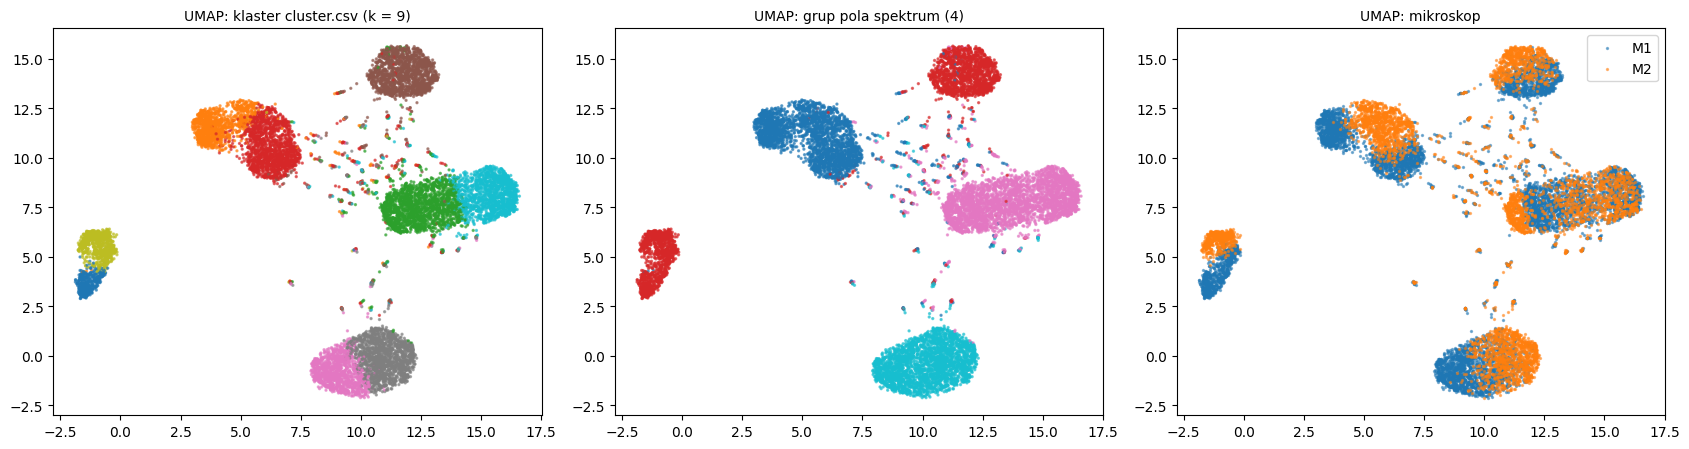

In [12]:
# UMAP/t-SNE pada fusi_simclr_concat: warna menurut klaster k = 9, grup pola, dan mikroskop
try:
    import umap
except ImportError:
    !pip -q install umap-learn
    try: import umap
    except ImportError: umap = None
vi = np.random.RandomState(SEED).choice(len(lab9), 12000, replace=False)
if umap is not None:
    P = umap.UMAP(n_neighbors=30, min_dist=0.2, random_state=SEED).fit_transform(E_f[vi]); nm_proj = 'UMAP'
else:
    from sklearn.manifold import TSNE
    P = TSNE(2, init='pca', random_state=SEED).fit_transform(E_f[vi][:6000]); vi = vi[:6000]; nm_proj = 't-SNE'
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, v, t in ((ax[0], lab9[vi], f'klaster cluster.csv (k = {K9})'), (ax[1], grp_sampel[vi], f'grup pola spektrum ({n_grp})')):
    a.scatter(P[:, 0], P[:, 1], c=v, cmap='tab10', s=2, alpha=.6); a.set_title(f'{nm_proj}: {t}', fontsize=10)
for m in sorted(np.unique(mik)):
    s = mik[vi] == m; ax[2].scatter(P[s, 0], P[s, 1], s=2, alpha=.5, label=m)
ax[2].legend(); ax[2].set_title(f'{nm_proj}: mikroskop', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Kandidat `cluster_k4.csv` dan kesimpulan

Kandidat ditulis ke `hasil/cluster_k4.csv` dengan kolom yang sama seperti `cluster.csv` (`id_sampel,cluster`). **`cluster.csv` di akar repositori tidak diubah.** Jika kelompok memutuskan memakai kandidat, berkas itu disalin ke `cluster.csv` pada PR terpisah, dan laporan menyebutkan alasannya serta bahwa keputusan diambil setelah melihat data.

In [13]:
sub4 = pd.DataFrame({'id_sampel': meta['id_sampel'].values, 'cluster': lab4.astype(int)})
assert len(sub4) == len(meta) and sub4['id_sampel'].is_unique and sub4['cluster'].nunique() == n_grp
sub4.to_csv(f'{OUT}/cluster_k4.csv', index=False)
print("tersimpan:", f'{OUT}/cluster_k4.csv', "| ukuran klaster:", dict(sub4['cluster'].value_counts().sort_index()))
with open(f'{OUT}/task3_verifikasi.json', 'w') as f: json.dump(INFO, f, indent=2, default=float)

tersimpan: /content/UTSDEEPLEARNING/kode/task3_cluster/hasil/cluster_k4.csv | ukuran klaster: {0: np.int64(8675), 1: np.int64(8551), 2: np.int64(10107), 3: np.int64(8667)}


In [14]:
from IPython.display import Markdown, display
def _f(x, n=3): return f"{x:.{n}f}".replace('.', ',')
t = []
gp = INFO['grup_pola']
t.append(f"**1. Pola spektrum.** {K9} klaster pada `cluster.csv` hanya memiliki **{gp['n']} pola spektrum yang berbeda** pada ambang korelasi {AMBANG_KORELASI} (celah terbesar antar penggabungan menunjuk {INFO['jumlah_pola_celah_terbesar']} pola). Pemetaan klaster ke grup pola: {gp['peta']}.")
dgg = pd.DataFrame(INFO['mikroskop_dalam_grup'])
multi = dgg[dgg['klaster'].apply(len) > 1]
if len(multi):
    j = ', '.join(f"grup {int(r.grup)} (klaster {r.klaster}, NMI pembagian-mikroskop {_f(r.nmi_pembagian_vs_mikroskop)})" for r in multi.itertuples())
    t.append(f"**2. Mikroskop di dalam grup.** Untuk grup yang terdiri atas lebih dari satu klaster, NMI antara pembagian di dalam grup dan mikroskop: {j}. Nilai yang tinggi berarti pembagian di dalam grup itu sebagian besar mengikuti alat.")
tb = pd.DataFrame(INFO['perbandingan'])
a9, a4 = tb.iloc[0], tb.iloc[1]
t.append(f"**3. Perbandingan.** `cluster.csv` (k = {int(a9.k)}): silhouette pada fusi_simclr_concat {_f(a9['sil_fusi_simclr_concat'])}, pada pca_spektrum {_f(a9['sil_pca_spektrum'])}, NMI mikroskop {_f(a9.nmi_mikroskop)}. Digabung menurut pola spektrum (k = {int(a4.k)}): {_f(a4['sil_fusi_simclr_concat'])}, {_f(a4['sil_pca_spektrum'])}, NMI mikroskop {_f(a4.nmi_mikroskop)}. ARI antara keduanya {_f(INFO['ari_k9_vs_gabungan'])} (NMI {_f(INFO['nmi_k9_vs_gabungan'])}).")
t.append("**4. Yang tidak dapat disimpulkan.** Seluruh ukuran bersifat internal. Pola spektrum yang sama pada beberapa klaster menunjukkan bahwa klaster-klaster itu tidak dibedakan oleh komposisi, tetapi tidak membuktikan bahwa tipe material sebenarnya berjumlah sama dengan jumlah pola: dua tipe material dapat saja berkomposisi sama dan berbeda pada mikrostruktur. Kandidat hasil penggabungan dan `cluster.csv` sama-sama tidak dapat dinilai terhadap acuan tersembunyi; pilihan di antara keduanya adalah keputusan yang diambil dari bukti tidak langsung dan dilaporkan sebagai keterbatasan.")
display(Markdown('\n\n'.join(t)))
open(f'{OUT}/kesimpulan_task3_verifikasi.md', 'w').write('\n\n'.join(t))

**1. Pola spektrum.** 9 klaster pada `cluster.csv` hanya memiliki **4 pola spektrum yang berbeda** pada ambang korelasi 0.98 (celah terbesar antar penggabungan menunjuk 4 pola). Pemetaan klaster ke grup pola: {0: 1, 1: 0, 2: 2, 3: 0, 4: 1, 5: 3, 6: 3, 7: 1, 8: 2}.

**2. Mikroskop di dalam grup.** Untuk grup yang terdiri atas lebih dari satu klaster, NMI antara pembagian di dalam grup dan mikroskop: grup 0 (klaster [1, 3], NMI pembagian-mikroskop 0,028), grup 1 (klaster [0, 4, 7], NMI pembagian-mikroskop 0,118), grup 2 (klaster [2, 8], NMI pembagian-mikroskop 0,000), grup 3 (klaster [5, 6], NMI pembagian-mikroskop 0,252). Nilai yang tinggi berarti pembagian di dalam grup itu sebagian besar mengikuti alat.

**3. Perbandingan.** `cluster.csv` (k = 9): silhouette pada fusi_simclr_concat 0,156, pada pca_spektrum -0,003, NMI mikroskop 0,049. Digabung menurut pola spektrum (k = 4): 0,143, 0,150, NMI mikroskop 0,000. ARI antara keduanya 0,592 (NMI 0,787).

**4. Yang tidak dapat disimpulkan.** Seluruh ukuran bersifat internal. Pola spektrum yang sama pada beberapa klaster menunjukkan bahwa klaster-klaster itu tidak dibedakan oleh komposisi, tetapi tidak membuktikan bahwa tipe material sebenarnya berjumlah sama dengan jumlah pola: dua tipe material dapat saja berkomposisi sama dan berbeda pada mikrostruktur. Kandidat hasil penggabungan dan `cluster.csv` sama-sama tidak dapat dinilai terhadap acuan tersembunyi; pilihan di antara keduanya adalah keputusan yang diambil dari bukti tidak langsung dan dilaporkan sebagai keterbatasan.

1543

## 6. Commit hasil

In [15]:
%cd /content/UTSDEEPLEARNING
!git add kode/task3_cluster/hasil
!git commit -m "Task 3 verifikasi: distorsi data, pola spektrum per klaster, uji k = 4 terhadap k = 9, kandidat cluster_k4.csv"
!git push origin task3-verifikasi

/content/UTSDEEPLEARNING
[task3-verifikasi 026eb05] Task 3 verifikasi: distorsi data, pola spektrum per klaster, uji k = 4 terhadap k = 9, kandidat cluster_k4.csv
 3 files changed, 36216 insertions(+)
 create mode 100644 kode/task3_cluster/hasil/cluster_k4.csv
 create mode 100644 kode/task3_cluster/hasil/kesimpulan_task3_verifikasi.md
 create mode 100644 kode/task3_cluster/hasil/task3_verifikasi.json
Enumerating objects: 12, done.
Counting objects: 100% (12/12), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 144.93 KiB | 3.22 MiB/s, done.
Total 8 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 4 local objects.
remote: 
remote: Create a pull request for 'task3-verifikasi' on GitHub by visiting:
remote:      https://github.com/rafiptrnto/UTSDEEPLEARNING/pull/new/task3-verifikasi
remote: 
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
 * [new branch]      task3-verifi